---
title: "Combining Plots with Subplots"
subtitle: "DS 2023 | Communicating with Data"
---

<img src="https://virginia.box.com/shared/static/b212jb6koum89zvamojiik28e507rn6n.png"/>

## Overview

So far in this course, we have seen many figures with several plots side by side.

This is a **powerful visual device**: aligning plots that depict **the same data** but through **different lenses**.

This notebook looks closely at how subplotting works.

Recall that in Matplotlib, a **figure** is the whole image, the canvas.

An **axes** is one plotting region inside the figure, with its own x axis, y axis, and data.

A figure can hold any number of axes.

When it holds several axes, we call them **subplots**.

We also call the **regions in the figure** where the plots live **panels**.

Matplotlib gives us two main ways to define and arrange panels:

- `plt.subplots()` arranges axes in a regular grid and returns them as an array, indexed by row and column.
- `plt.subplot_mosaic()` lets us *draw* the layout with labels and returns the axes as a dictionary, indexed by name.

The second method was added in Matplotlib 3.4, and it makes irregular layouts much easier.

## Use Cases

**Small multiples**: the same plot for each group, such as one histogram per penguin species or one line per country.

**Different views of the same data**: a scatter plot with histograms of each variable along its edges.

**Before and after**: raw data next to transformed data, or one parameter setting next to another.

**Summary figures**: one large plot that tells the main story, with smaller plots that support it, as in a report or a poster.

**Juxtaposition**: visually aligning **different plots** that elucidate different aspects of the **same structure**.

## Set Up

We will work with familiar data.

In [63]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [64]:
penguins = sns.load_dataset('penguins').dropna()
healthexp = sns.load_dataset('healthexp')
flights = sns.load_dataset('flights')

## Creating Subplots from Scratch

Let's start by placing axes by hand.

A figure has its own coordinate system, running from $0$ to $1$ in each direction, with $(0, 0)$ at the bottom left.

`fig.add_axes()` takes a rectangle in these coordinates, written as `[lower_x, lower_y, width, height]`, and puts an axes there.

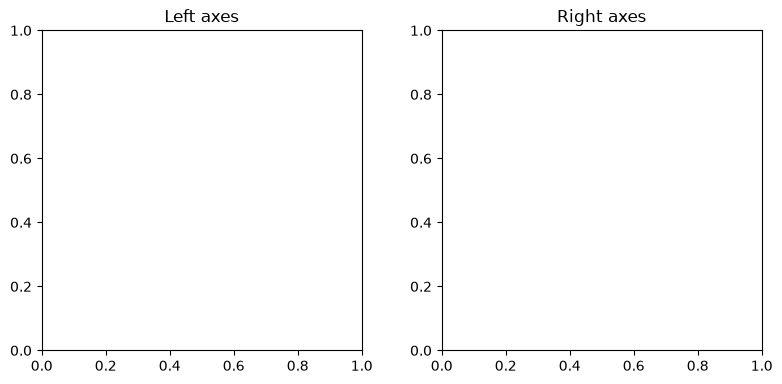

In [171]:
fig = plt.figure(figsize=(8, 4))

#                   x     y    w    h
ax1 = fig.add_axes([0.05, 0.1, 0.4, 0.8])
ax2 = fig.add_axes([0.55, 0.1, 0.4, 0.8])

ax1.set_title('Left axes')
ax2.set_title('Right axes')

plt.show()

**Every layout method in Matplotlib does exactly this, ultimately.**

It works out a rectangle for each axes and places it on the figure.

Let's draw two real plots this way.

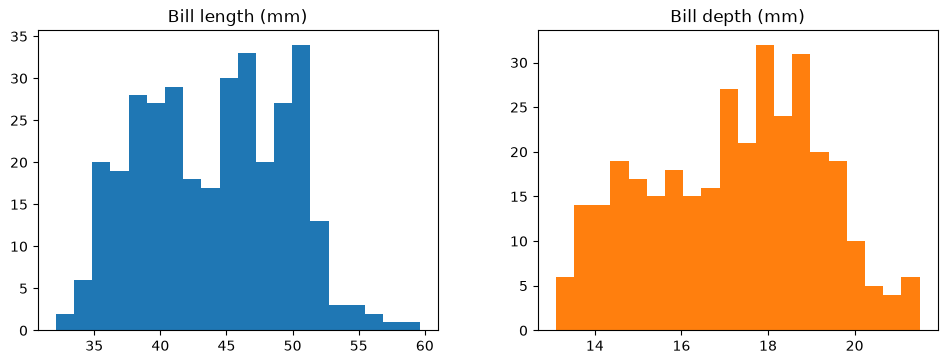

In [172]:
fig = plt.figure(figsize=(10, 4))

#                   x     y     w    h
ax1 = fig.add_axes([0.07, 0.15, 0.4, 0.75])
ax2 = fig.add_axes([0.57, 0.15, 0.4, 0.75])

ax1.hist(penguins.bill_length_mm, bins=20, color='tab:blue')
ax1.set_title('Bill length (mm)')

ax2.hist(penguins.bill_depth_mm, bins=20, color='tab:orange')
ax2.set_title('Bill depth (mm)')

plt.show()

This gives us complete control.

But it is tedious.

We had to compute every margin and every width ourselves, and if we add a third plot, we must recompute all of them.

What we really want is to say *what* the arrangement is, and let Matplotlib work out the rectangles.

## Using `plt.subplots()`

`plt.subplots()` takes a number of rows and a number of columns.

It returns two things: the figure, and the axes.

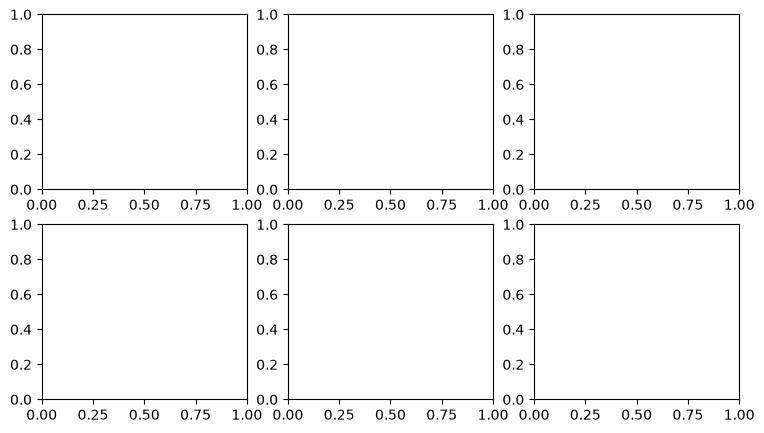

In [67]:
fig, ax = plt.subplots(2, 3, figsize=(9, 5))
plt.show()

The axes come back as a NumPy array with the same shape as the grid.

In [68]:
ax.shape

(2, 3)

So we reach each axes by its row and column, counting from 0.

`ax[0, 0]` is the top left, and `ax[1, 2]` is the bottom right.

Let's label every cell with its index so we can see the pattern.

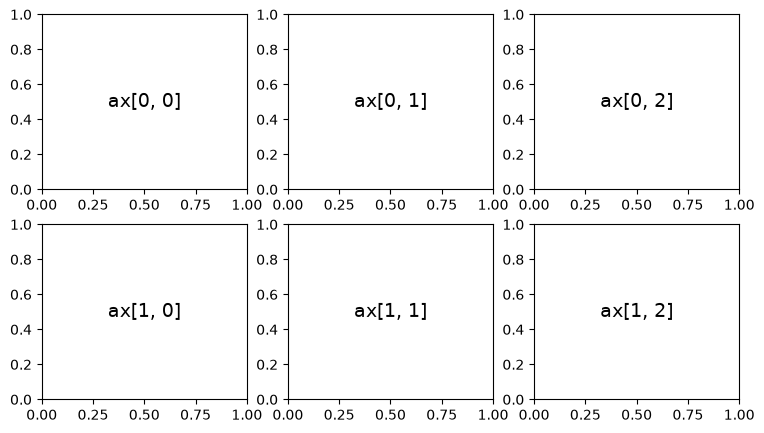

In [69]:
fig, ax = plt.subplots(2, 3, figsize=(9, 5))

for i in range(2):
    for j in range(3):
        ax[i, j].text(0.5, 0.5, f'ax[{i}, {j}]', ha='center', va='center', fontsize=14)

plt.show()

```{important}

The shape of the axes array depends on the grid.

A grid with one row or one column returns a one-dimensional array, so we write `ax[0]`, not `ax[0, 0]`.

A 1 × 1 grid returns a single axes, not an array at all.

This is the `squeeze` parameter at work; `squeeze=False` always returns a 2-D array.
```

### A simple example

Let's draw one histogram of body mass for each species.

There are three species, so we create a figure with one row of three axes.

Even though we know we can use `subplots` with Pandas, we will use a loop to demonstrate the use of pre-defined axes.

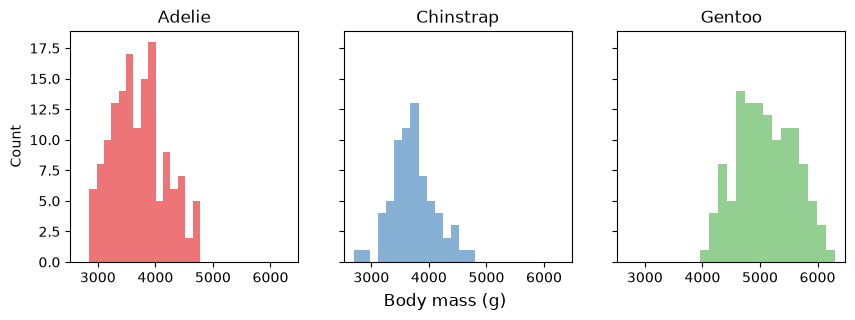

In [169]:
cmap = plt.get_cmap('Set1')

fig, ax = plt.subplots(1, 3, figsize=(10, 3), sharex=True, sharey=True)

for i, species in enumerate(penguins.species.unique()):
    penguins.loc[penguins.species == species, 'body_mass_g']\
        .plot.hist(bins=15, ax=ax[i], color=cmap(i), alpha=.6, title=species)

ax[0].set_ylabel('Count')
fig.supxlabel('Body mass (g)', y=-.05)
plt.show()

Notice that the parameters `sharex=True` and `sharey=True` give every axes the same x range and the same y range.

Sharing axes allows us to compare the panels directly.

For example, we can see that Gentoos are heavier than the other two species because its mass is farther to the right of the scale shared by all three plots.

### Subplots with Pandas

As mentioned, Pandas' `plot` method has a `subplots` argument, which handles the suplotting for you with arguments passed directly to `plot`.

Note that since we didn't use `plt.subplots`, we didn't get a `fig` object to use to provide a figure-level x axis label.

Instead, we use `plt.gcf` to get the current figure.

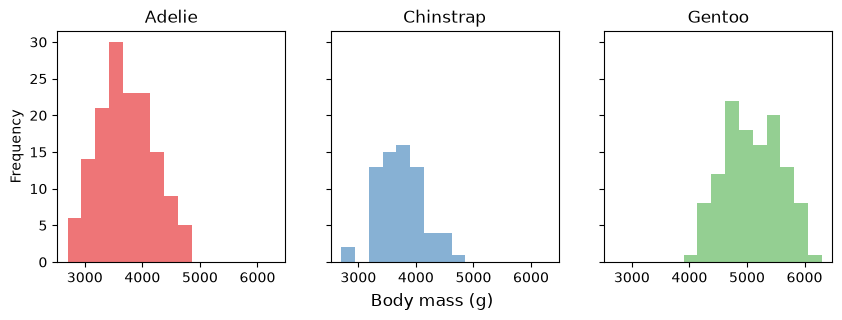

In [173]:
penguins_wide1 = penguins.pivot(columns='species', values='body_mass_g')
ax = penguins_wide1.plot.hist(
        subplots=True, layout=(1,3), figsize=(10, 3),
        bins=15, legend=False, 
        title=penguins_wide1.columns.to_list(),
        sharey=True, sharex=True,
        color=[cmap(i) for i in range(penguins_wide1.shape[1])],
        alpha=.6
)
plt.gcf().supxlabel('Body mass (g)', y=-.05)
plt.show()

Pandas' plotting methods can also take an `ax` parameter.

So we can create the grid with Matplotlib and let Pandas fill each axes.

Here is the airline passengers table from *Heatmaps*, drawn two ways.

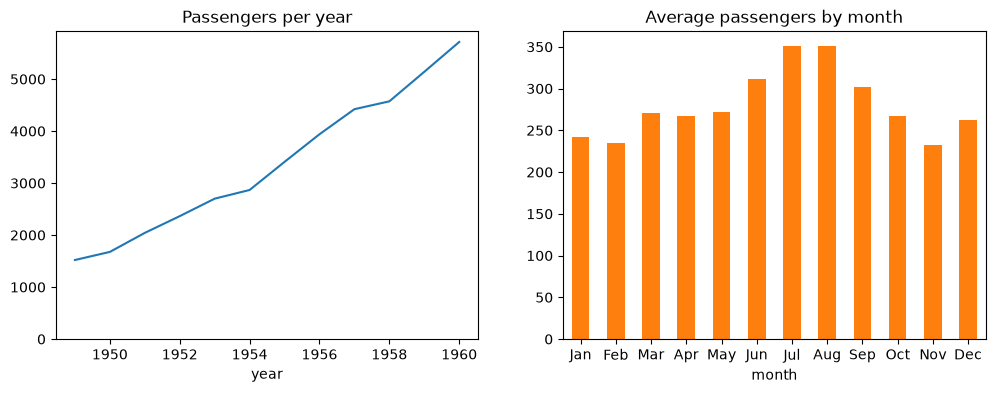

In [148]:
passengers = flights.pivot(index='year', columns='month', values='passengers')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

passengers.sum(axis=1).plot(ax=ax[0], title='Passengers per year', color='tab:blue')
passengers.mean().plot.bar(ax=ax[1], title='Average passengers by month', color='tab:orange', rot=0)

ax[0].set_ylim(0)
plt.show()

This division of labor is the one we will use throughout: **Matplotlib builds the layout, and Pandas draws the plots**.

### Flattening the grid

When the grid has more than one row, it is often easier to loop over a flat list of axes.

`ax.flat` walks through the array row by row.

Here is life expectancy for each of the six countries in `healthexp`, in a 2 × 3 grid.

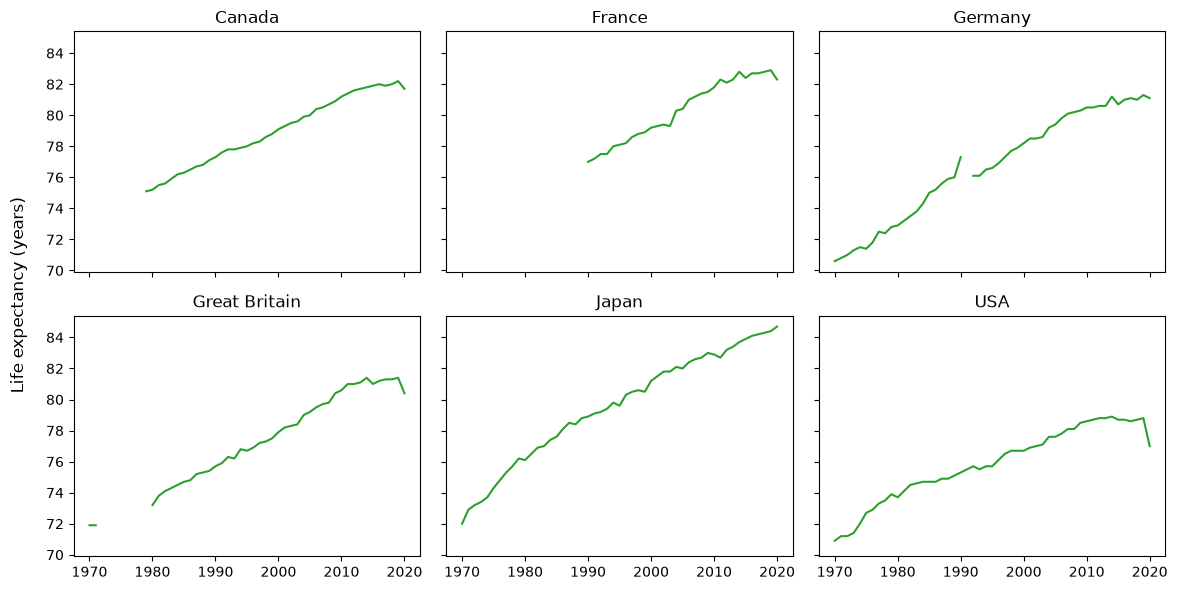

In [176]:
life = healthexp.pivot(index='Year', columns='Country', values='Life_Expectancy')

fig, ax = plt.subplots(2, 3, figsize=(12, 6), sharex=True, sharey=True)

for i, my_ax in enumerate(ax.flat):
    country = life.columns[i]
    life[country].plot(ax=my_ax, title=country, color='tab:green')
    my_ax.set_xlabel('')

fig.supylabel('Life expectancy (years)')
plt.tight_layout()
plt.show()

What do you notice when you compare the USA panel with Japan's?

Because the y axes are shared, the comparison is honest.

### Where `plt.subplots()` gets awkward

**Left-over panels**

`plt.subplots()` is perfect for regular grids, i.e. where each row has the same number of axes.

But real figures are often not regular.

If we have five plots, a 2 × 3 grid leaves one axes empty, and Matplotlib still draws its frame.

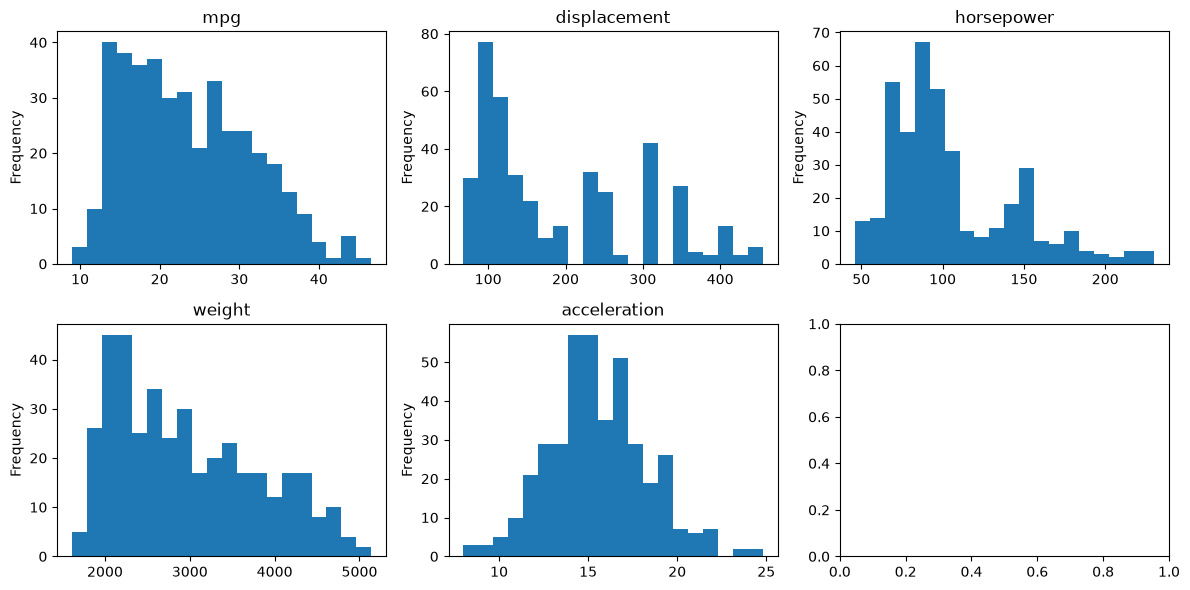

In [178]:
mpg = sns.load_dataset('mpg')
measures = ['mpg', 'displacement', 'horsepower', 'weight', 'acceleration']

fig, ax = plt.subplots(2, 3, figsize=(12, 6))

for i, m in enumerate(measures):
    mpg[m].plot.hist(ax=ax.flat[i], bins=20, color='tab:blue', title=m)

plt.tight_layout()
plt.show()

The sixth axes is empty, but its frame and tick labels are still there.

We have to remember to remove it ourselves, with `set_axis_off()`.

And if we later add or drop a measure, we have to rethink the grid.

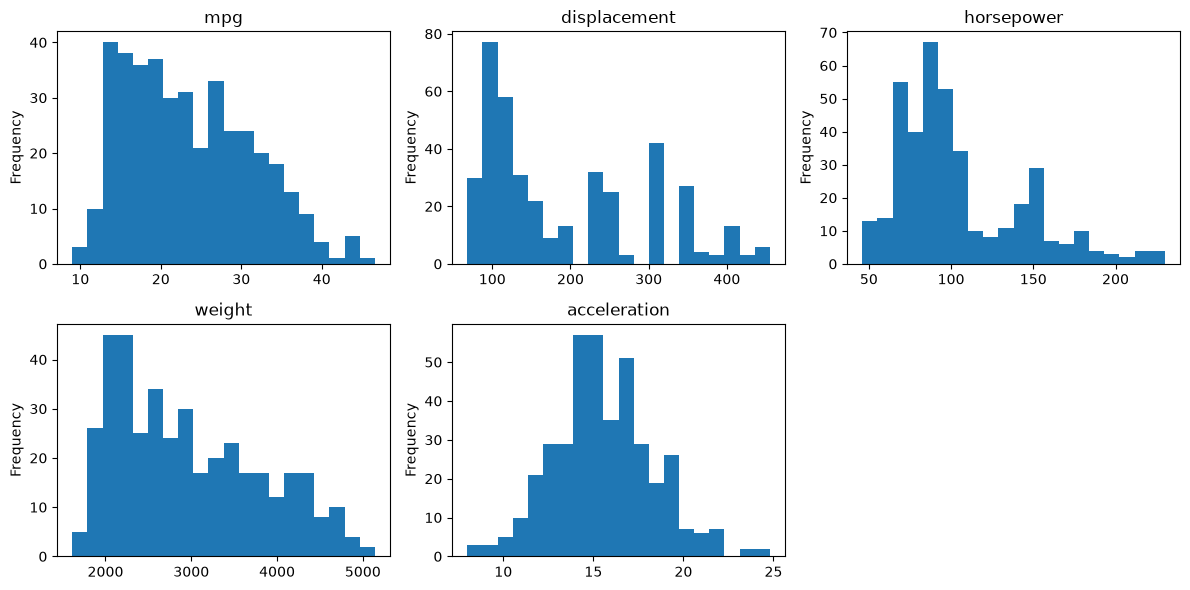

In [180]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6))

for i, m in enumerate(measures):
    mpg[m].plot.hist(ax=ax.flat[i], bins=20, color='tab:blue', title=m)

# ax[1, 2].set_axis_off() # Also possible
ax.flat[-1].set_axis_off() 

plt.tight_layout()
plt.show()

**Spanning cells** 

Suppose we want one wide plot on top and two smaller plots below it.

That layout is not a regular grid, so `plt.subplots()` cannot make it.

One solution is to use a **GridSpec** object, which describes the grid separately from the axes.

GridSpect allow us to place an axes on a *slice* of the grid, using the same slicing syntax as a NumPy array.

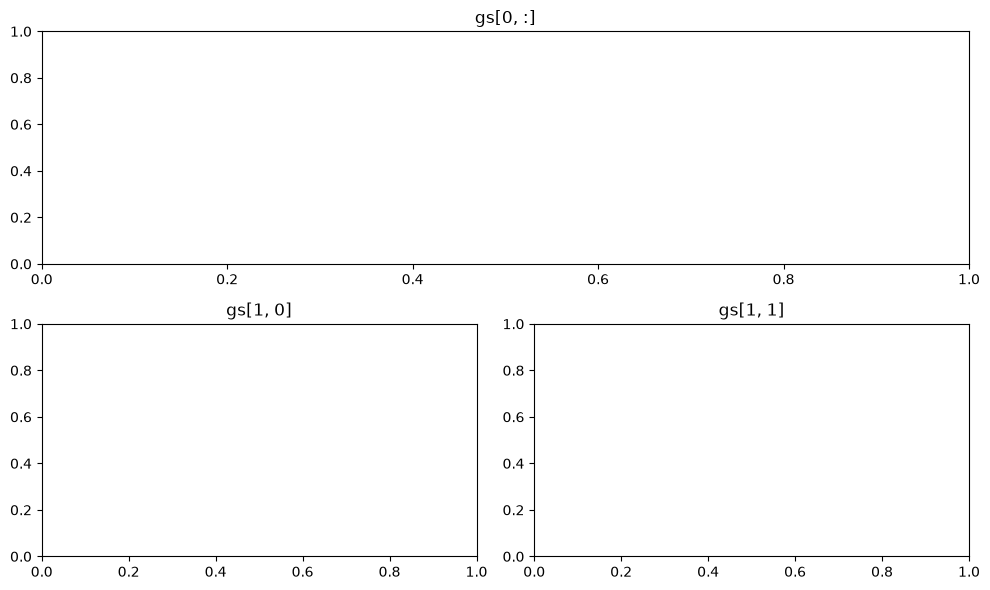

In [183]:
fig = plt.figure(figsize=(10, 6))

# GridSpec 
gs = fig.add_gridspec(2, 2)

top = fig.add_subplot(gs[0, :]) # Slice syntax that returns row 0, all (:) columns
bottom_left = fig.add_subplot(gs[1, 0])
bottom_right = fig.add_subplot(gs[1, 1])

top.set_title('gs[0, :]')
bottom_left.set_title('gs[1, 0]')
bottom_right.set_title('gs[1, 1]')

plt.tight_layout()
plt.show()

This works, but notice how the structure of the code does not mirror the structure of the figure.

To understand the layout, we have to read the slices and picture the result in our heads.

**Indexing by position** 

Finally, `ax[1, 0]` tells us *where* an axes is, but not *what* it shows.

If we rearrange the figure, every index in the code must change with it, and a mistake puts a plot in the wrong place without any error.

## A better way: using `plt.subplot_mosaic()`

`plt.subplot_mosaic()` solves all three problems with one idea.

Instead of giving the number of rows and columns, we **draw the layout** as a list of lists, one inner list per row.

Each entry is a label, and each label becomes one axes.

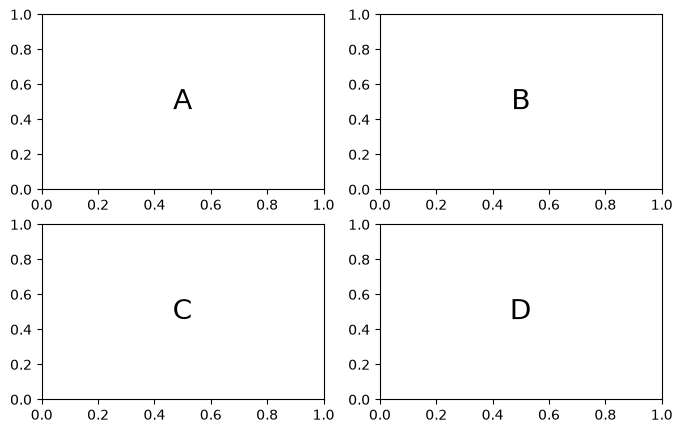

In [184]:
layout = [
    ['A', 'B'],
    ['C', 'D'],
]

fig, axd = plt.subplot_mosaic(layout, figsize=(8, 5))

for label, a in axd.items():
    a.text(0.5, 0.5, label, ha='center', va='center', fontsize=20)

plt.show()

The axes come back as a **dictionary**, not an array.

Its keys are the axes labels.

In [185]:
axd

{'A': <Axes: label='A'>,
 'B': <Axes: label='B'>,
 'C': <Axes: label='C'>,
 'D': <Axes: label='D'>}

So we reach each axes by name: `axd['C']`, not `ax[1, 0]`.

```{tip}
Do not rely on the order of the dictionary's keys.

Always reach an axes by its label, or loop over a list of labels that you control.
```

If you use single characters for labels, we can write the layout as a string instead.

Rows are separated by semicolons, or by new lines.

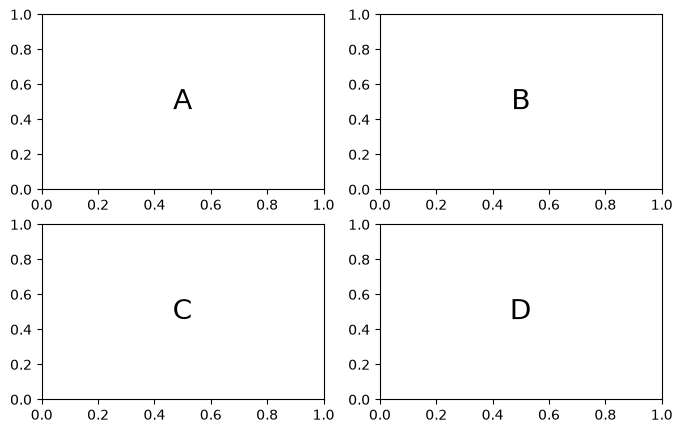

In [186]:
fig, axd = plt.subplot_mosaic('AB;CD', figsize=(8, 5))

for label, a in axd.items():
    a.text(0.5, 0.5, label, ha='center', va='center', fontsize=20)

plt.show()

### Spanning cells

To make an axes span several cells, we repeat its label.

Here is the wide-top layout we built with GridSpec.

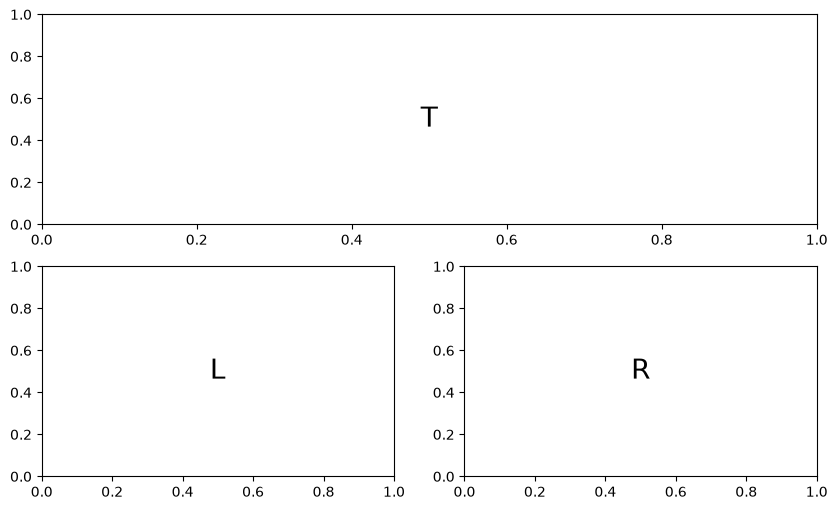

In [188]:
# layout = 

layout = """
    TT
    LR
    """

fig, axd = plt.subplot_mosaic(layout, figsize=(10, 6))

for label, a in axd.items():
    a.text(0.5, 0.5, label, ha='center', va='center', fontsize=20)

plt.show()

Now the code *looks like* the figure.

`T` fills both cells of the top row, so it becomes one wide axes.

A label's cells must form a rectangle.

An L-shaped region, for example, raises an error.

### Leaving cells empty

A period, `'.'`, marks a cell with no axes.

This solves the leftover-cell problem: we simply leave the cell out of the drawing.

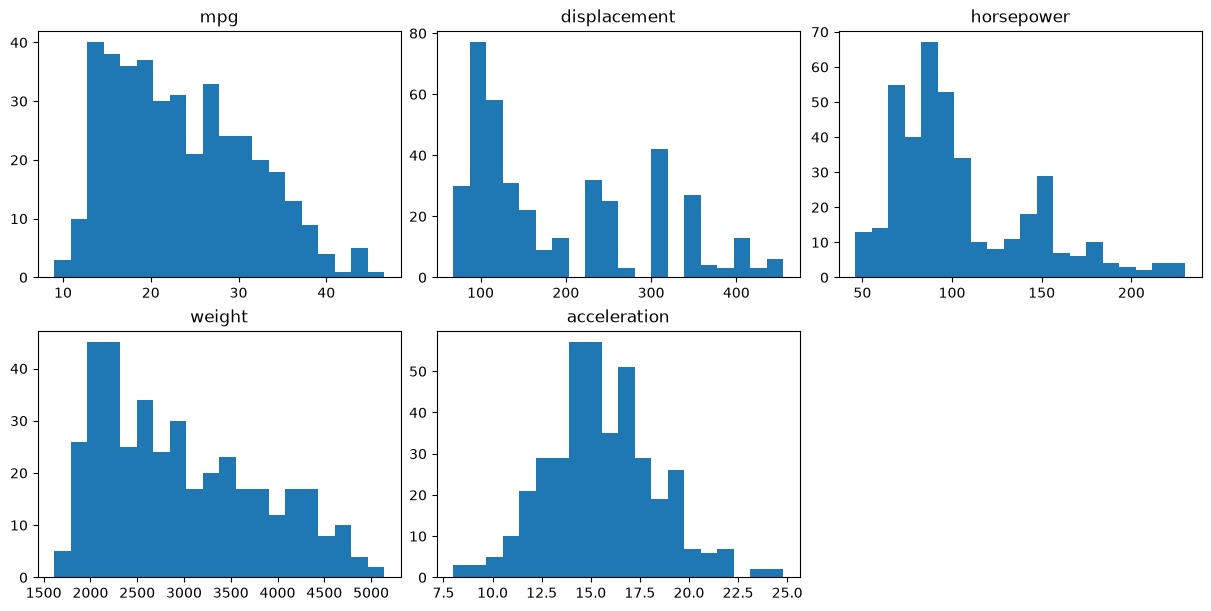

In [107]:
layout = [
    ['mpg',    'displacement', 'horsepower'],
    ['weight', 'acceleration', '.'],
]

fig, axd = plt.subplot_mosaic(layout, figsize=(12, 6), layout='constrained')

for m in measures:
    axd[m].hist(mpg[m].dropna(), bins=20, color='tab:blue')
    axd[m].set_title(m)

plt.show()

Notice that the labels are now the column names themselves.

Labels can be any strings, so they can describe what each axes *shows*.

This is sometimes called **semantic** layout: the code names the plots by their meaning, not their position.

We also passed `layout='constrained'`.

This asks Matplotlib to fit titles, labels, and colorbars without overlap, like `plt.tight_layout()`, but it is applied every time the figure is drawn.

It works with `plt.subplots()` too.

### Sizing rows and columns

By default, every row has the same height and every column the same width.

`width_ratios` and `height_ratios` change that.

They give the relative sizes, so `[3, 1]` makes the first column three times as wide as the second.

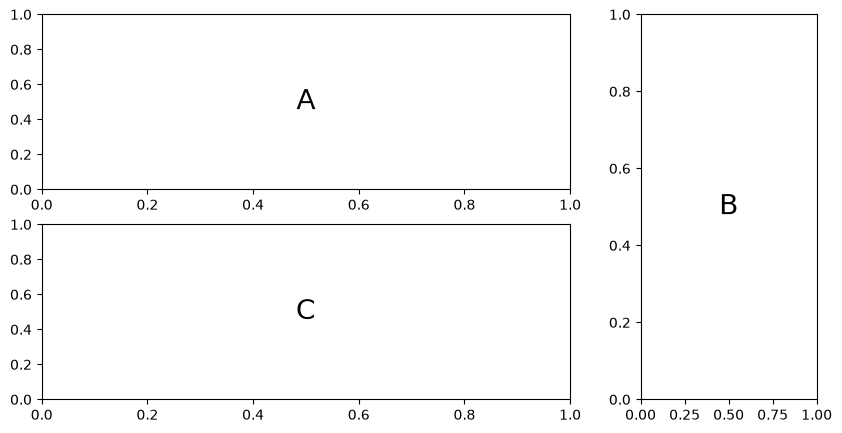

In [108]:
fig, axd = plt.subplot_mosaic('AB;CB', figsize=(10, 5), width_ratios=[3, 1])

for label, a in axd.items():
    a.text(0.5, 0.5, label, ha='center', va='center', fontsize=20)

plt.show()

## Examples

### A simple example

Let's make a summary figure for `healthexp`.

The main story is health spending over time, so it gets the wide top panel.

Two smaller panels support it: spending in the most recent year, and life expectancy against spending.

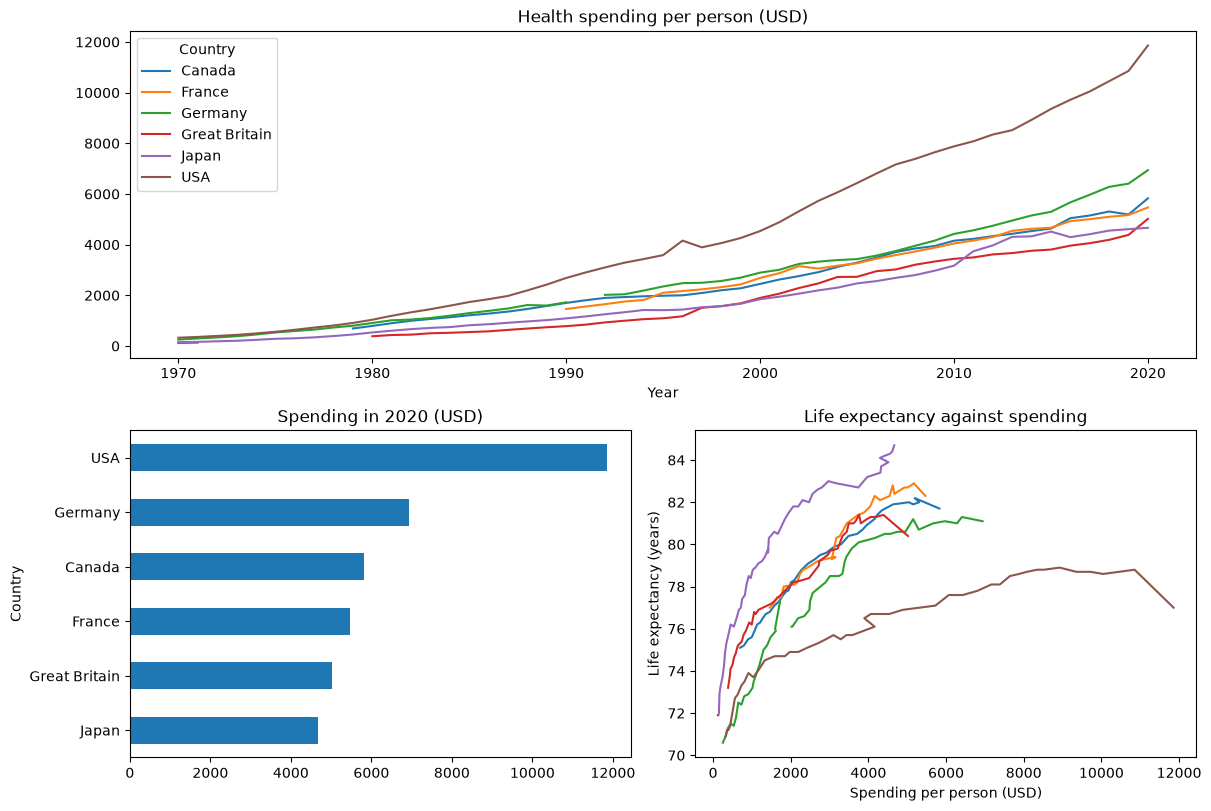

In [109]:
spending = healthexp.pivot(index='Year', columns='Country', values='Spending_USD')

layout = [
    ['trend', 'trend'],
    ['recent', 'relation'],
]

fig, axd = plt.subplot_mosaic(layout, figsize=(12, 8), layout='constrained')

spending.plot(ax=axd['trend'], title='Health spending per person (USD)')

spending.loc[2020].sort_values().plot.barh(ax=axd['recent'], color='tab:blue', title='Spending in 2020 (USD)')

for country in spending.columns:
    axd['relation'].plot(spending[country], life[country], label=country)

axd['relation'].set_xlabel('Spending per person (USD)')
axd['relation'].set_ylabel('Life expectancy (years)')
axd['relation'].set_title('Life expectancy against spending')

plt.show()

Each panel was drawn by Pandas or Matplotlib exactly as it would be on its own.

All we changed was the `ax=` argument.

The bottom right panel needs no legend of its own: Matplotlib assigns colors to the countries in the same order in both panels, so the top legend serves for both.

Notice how the bottom right panel puts the top panel's story in context.

The USA spends far more than any other country, but its life expectancy is the lowest of the six.

```{note}
The gaps in the top panel are years missing from the data.
Pandas leaves a break in the line rather than drawing across a missing value.
```

### A more complex example

A common figure in exploratory analysis is a scatter plot with a histogram of each variable along its edges.

These edge plots are called **marginal distributions**, because they sit in the margins.

The layout has a large main panel, a short panel above it, a narrow panel to its right, and an empty corner.

With a mosaic, we can draw exactly that.

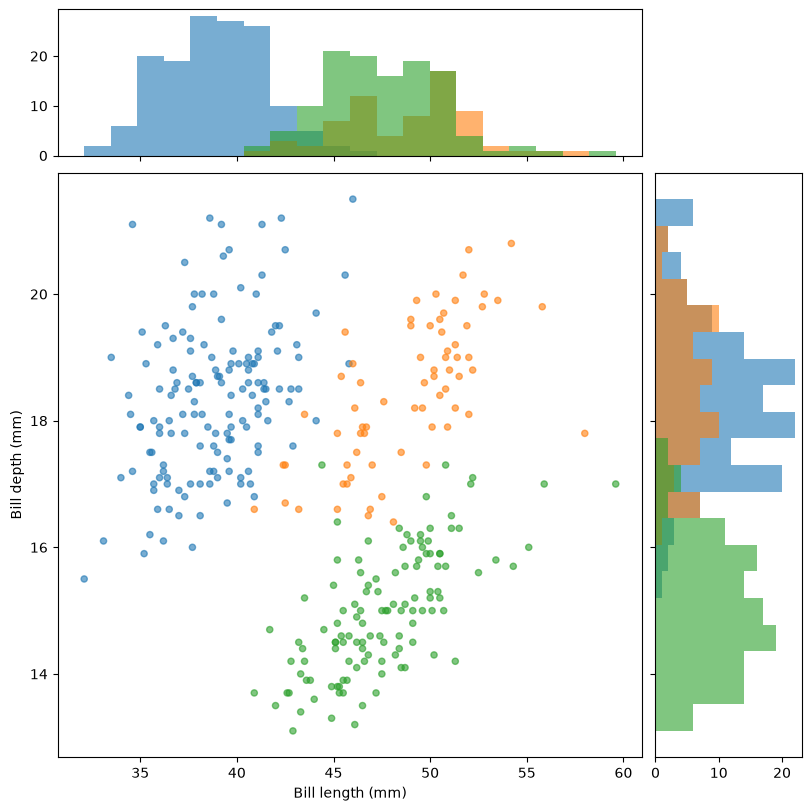

In [110]:
layout = [
    ['top',  '.'],
    ['main', 'right'],
]

fig, axd = plt.subplot_mosaic(
    layout, figsize=(8, 8),
    width_ratios=[4, 1], height_ratios=[1, 4],
    layout='constrained'
)

# Make the marginal plots share an axis with the main plot
axd['top'].sharex(axd['main'])
axd['right'].sharey(axd['main'])

# Define common colors
species_colors = {'Adelie': 'tab:blue', 'Chinstrap': 'tab:orange', 'Gentoo': 'tab:green'}

penguins.plot.scatter(ax=axd['main'], x='bill_length_mm', y='bill_depth_mm', color=penguins.species.map(species_colors), alpha=.6)
penguins.pivot(columns='species', values='bill_length_mm')\
    .plot.hist(ax=axd['top'], bins=20, color=species_colors.values(), legend=False, alpha=.6)
penguins.pivot(columns='species', values='bill_depth_mm')\
    .plot.hist(ax=axd['right'], bins=20, color=species_colors.values(), legend=False, alpha=.6, orientation='horizontal')

axd['main'].set_xlabel('Bill length (mm)')
axd['main'].set_ylabel('Bill depth (mm)')

axd['top'].tick_params(labelbottom=False)
axd['top'].set_ylabel("")
axd['right'].tick_params(labelleft=False)
axd['right'].set_xlabel("")

plt.show()

Each marginal histogram lines up with the axis it describes.

- That is what `sharex()` and `sharey()` do: they tie one axes' scale to another's.

- The right histogram uses `orientation='horizontal'` so that its bars run along the y axis.

Now look at the three views together.

- In the top margin, Chinstraps and Gentoos overlap in bill length.

- In the right margin, Adelies and Chinstraps overlap in bill depth.

- Only the scatter plot, which uses both variables, separates all three species.

```{tip}
Seaborn's `jointplot()`, which we met in *Introducing Seaborn*, makes this figure in one line.

Building it ourselves shows what `jointplot()` is doing, and lets us change any part of it.
```

## When Subplots Mislead

A figure with several panels invites readers to compare them.

So the design choices of the layout become claims about the data.

### Independent scales

By default, each axes chooses its own range to fit its own data.

Let's draw health spending by country without shared y axes.

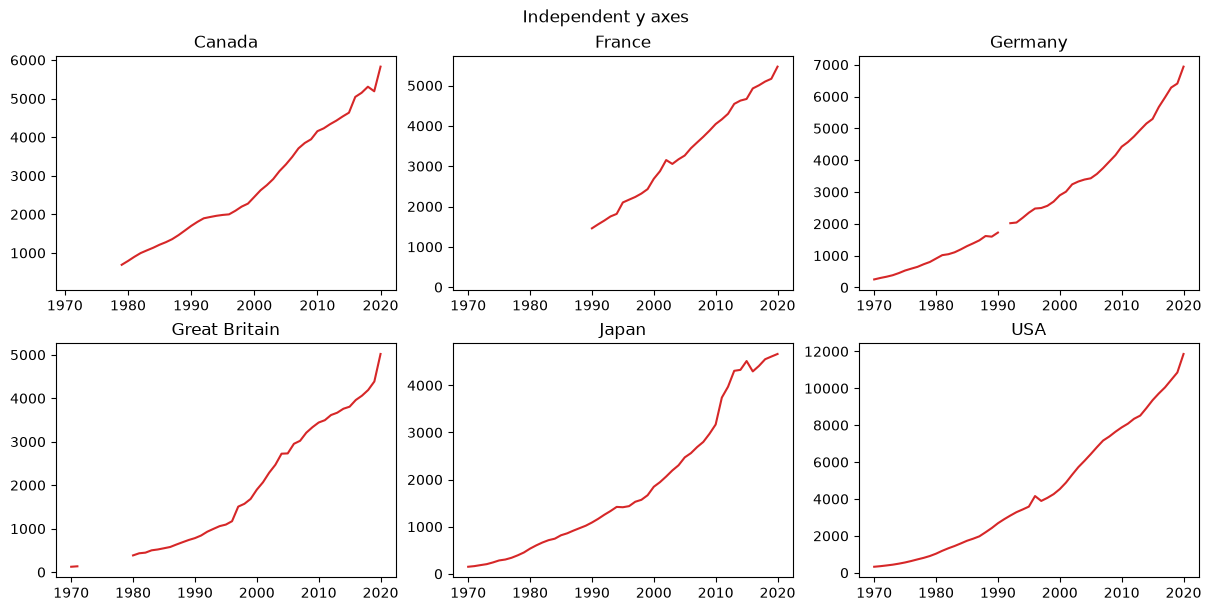

In [111]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6), layout='constrained')

for a, country in zip(ax.flat, spending.columns):
    spending[country].plot(ax=a, title=country, color='tab:red')
    a.set_xlabel('')

fig.suptitle('Independent y axes')
plt.show()

Every country seems to climb to about the same height.

But read the y axes: the tops range from a few thousand dollars to more than ten thousand.

The panels look alike only because each was stretched to fill its own box.

Now let's share the y axis.

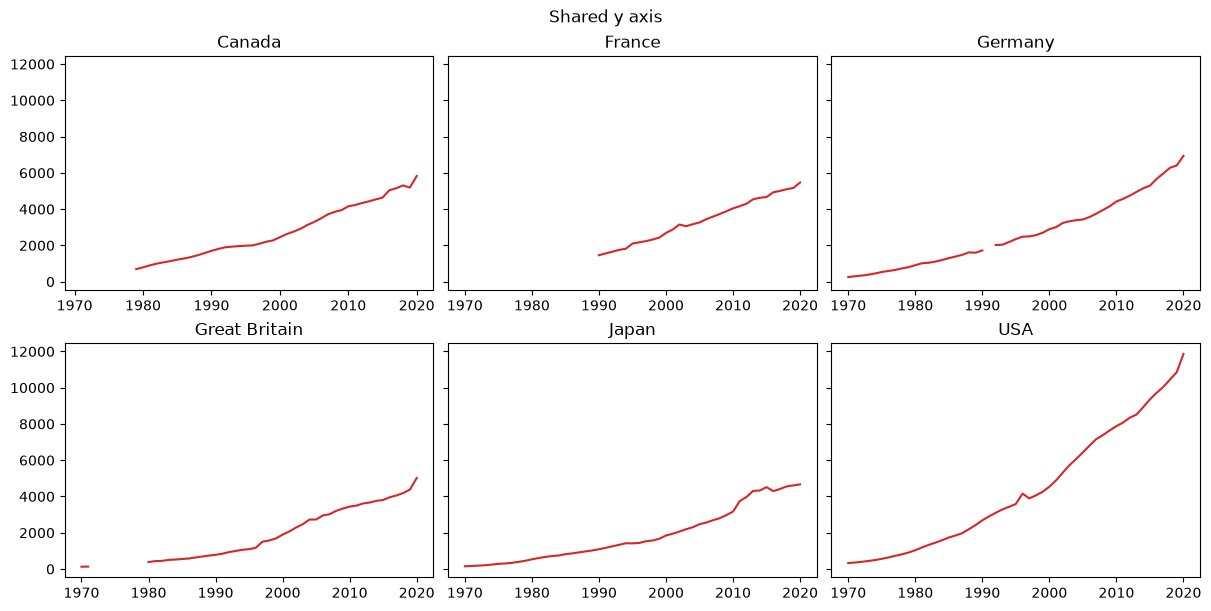

In [112]:
fig, ax = plt.subplots(2, 3, figsize=(12, 6), sharey=True, layout='constrained')

for a, country in zip(ax.flat, spending.columns):
    spending[country].plot(ax=a, title=country, color='tab:red')
    a.set_xlabel('')

fig.suptitle('Shared y axis')
plt.show()

Now the USA stands out immediately.

```{important}
When panels show the same measurement for different groups, share the axes.
Independent axes are appropriate when we care about the *shape* of each series, not its size, and then the figure should say so.
```

### Other pitfalls

- **Size implies importance.** A large panel draws the eye first. Give the most space to the main story, not to whichever plot happened to come first.
- **Position implies order.** Readers scan left to right and top to bottom. Arrange panels in a meaningful order, such as by time, by value, or by a natural sequence of categories.
- **Inconsistent encodings.** If a group is blue in one panel, it should be blue in every panel. Reusing a dictionary like `species_colors` keeps colors tied to groups, not positions.
- **Empty and duplicated labels.** Repeating the same axis label in every panel adds clutter. Use `fig.supxlabel()` and `fig.supylabel()` for labels the panels share.
- **Too many panels.** Small multiples work because each panel is simple. If each panel needs close study, the figure may be better as several figures.

## Summary

- A **figure** is the canvas, and each **axes** is one plotting region inside it. Several axes in one figure are **subplots**.
- Every layout method computes a rectangle for each axes, as `fig.add_axes()` does by hand.
- `plt.subplots(rows, cols)` makes a regular grid and returns the axes as an array indexed by position.
- `plt.subplot_mosaic()` takes a drawing of the layout and returns the axes as a dictionary indexed by label.
- In a mosaic, repeat a label to span cells, and use `'.'` for an empty cell.
- Matplotlib builds the layout, and Pandas fills each axes through its `ax=` parameter.
- Share axes when panels show the same measurement, so that comparisons are honest.

| Task | Code |
|---|---|
| Regular grid | `fig, ax = plt.subplots(2, 3)` |
| Shared scales | `plt.subplots(2, 3, sharex=True, sharey=True)` |
| Loop over a grid | `for a in ax.flat:` |
| Hide an unused axes | `ax[1, 2].set_axis_off()` |
| Drawn layout | `fig, axd = plt.subplot_mosaic([['A', 'A'], ['B', 'C']])` |
| String layout | `plt.subplot_mosaic('AA;BC')` |
| Empty cell | `'.'` in the layout |
| Relative sizes | `width_ratios=[3, 1]`, `height_ratios=[1, 4]` |
| Avoid overlaps | `layout='constrained'` |
| Tie one axes to another | `axd['top'].sharex(axd['main'])` |
| Draw with Pandas | `df.plot(ax=axd['trend'])` |
| Shared labels | `fig.supxlabel(...)`, `fig.supylabel(...)` |